## Load Dataset

In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv("india_disaster_prediction_dataset.csv")

print(df.head())
print(df.shape)
print(df.info())

   rainfall_mm  temperature_c  soil_moisture  elevation_m  slope_deg  \
0   259.605698      24.607526      15.009975   650.583398  26.497050   
1   183.408284      26.472503      98.719085  2776.843752   9.755691   
2   277.722625      25.013095      82.001663  1544.489345  36.656267   
3   382.763583      28.552090      88.192816  1443.299644  47.136293   
4   171.901595      33.985893      72.486485  2988.312266  40.002394   

   river_distance_km  population_density  flood  landslide  
0          13.925453         1620.727546      0          0  
1          44.656846         1522.797302      0          0  
2          48.900379          128.759067      0          1  
3          33.955996          341.306020      1          1  
4          48.514985         1477.775655      0          1  
(10000, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              ---------

## Check Missing Values

In [ ]:
print(df.isnull().sum())

rainfall_mm           0
temperature_c         0
soil_moisture         0
elevation_m           0
slope_deg             0
river_distance_km     0
population_density    0
flood                 0
landslide             0
dtype: int64


## Statistical Analysis

In [ ]:
print(df.describe())

        rainfall_mm  temperature_c  soil_moisture   elevation_m     slope_deg  \
count  10000.000000   10000.000000   10000.000000  10000.000000  10000.000000   
mean     202.196725      28.066991      54.577375   1497.236612     29.955278   
std      115.287501       5.001350      25.823040    868.309825     17.307789   
min        0.000000      10.000000      10.000498      0.050209      0.006283   
25%      119.289136      24.689945      32.066624    748.646479     14.971981   
50%      199.688603      28.079234      54.699419   1488.125621     30.126997   
75%      280.529707      31.469324      76.534702   2257.584949     44.933919   
max      671.148525      45.000000      99.981043   2999.916442     59.997417   

       river_distance_km  population_density        flood     landslide  
count       10000.000000        10000.000000  10000.00000  10000.000000  
mean           25.003930         1028.522548      0.30000      0.250000  
std            14.429596          557.853762    

## Correlation Analysis

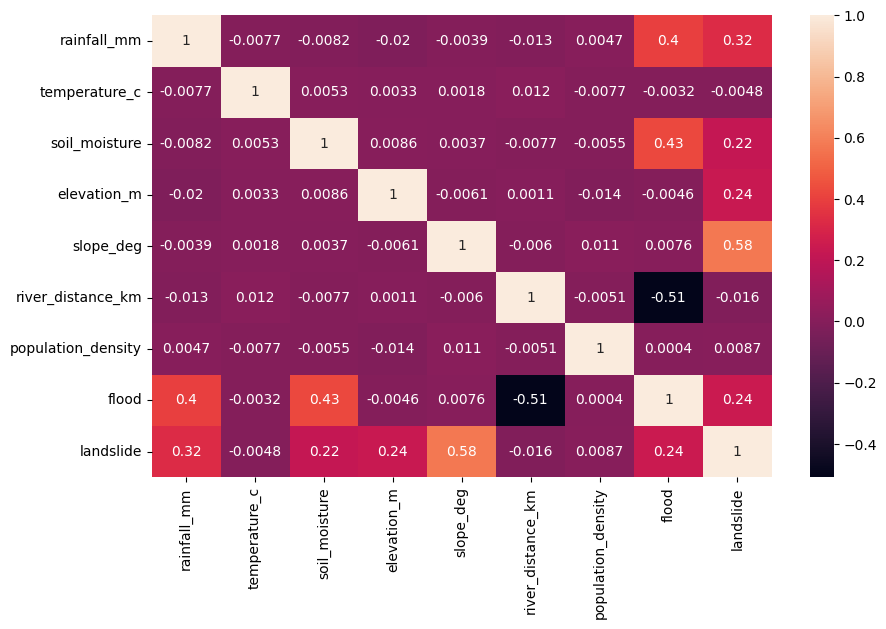

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))
sns.heatmap(df.corr(),annot=True)
plt.show()

## Feature & Target Separation

In [10]:
X = df.drop(["flood","landslide"],axis=1)
y = df[["flood","landslide"]]

## Train Test Split

In [11]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

## Train Multiple Models

In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier

## Random Forest

In [13]:
rf = RandomForestClassifier(n_estimators=200)

rf.fit(X_train,y_train)

RandomForestClassifier(n_estimators=200)

## Decision Tree

In [14]:
dt = DecisionTreeClassifier()

dt.fit(X_train,y_train)

DecisionTreeClassifier()

## Model Evaluation

In [15]:
from sklearn.metrics import accuracy_score

rf_pred = rf.predict(X_test)
dt_pred = dt.predict(X_test)

print("Random Forest Accuracy:",accuracy_score(y_test,rf_pred))
print("Decision Tree Accuracy:",accuracy_score(y_test,dt_pred))

Random Forest Accuracy: 0.9285
Decision Tree Accuracy: 0.8585


## Feature Importance

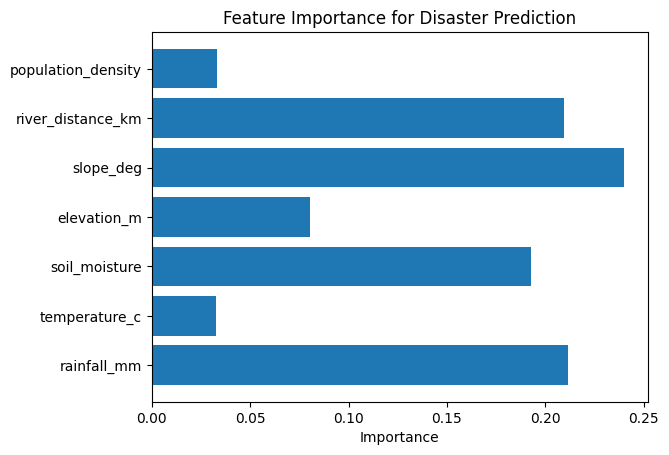

In [16]:
importance = rf.feature_importances_

features = X.columns

plt.barh(features,importance)
plt.xlabel("Importance")
plt.title("Feature Importance for Disaster Prediction")
plt.show()

## Hyperparameter Tuning

In [17]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "n_estimators":[100,200],
    "max_depth":[10,20,None]
}

grid = GridSearchCV(RandomForestClassifier(),param_grid,cv=3)

grid.fit(X_train,y_train)

best_model = grid.best_estimator_

## Save Model

In [18]:
import pickle

pickle.dump(best_model,open("disaster_model.pkl","wb"))

## Prediction Script

In [19]:
model = pickle.load(open("disaster_model.pkl","rb"))

sample = [[300,30,70,1000,40,5,800]]

prediction = model.predict(sample)

print(prediction)

[[1 1]]


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


In [20]:
import pickle

pickle.dump(best_model, open("disaster_model.pkl", "wb"))

print("Model saved successfully")

Model saved successfully


In [21]:
%%writefile predict.py

import pickle
import numpy as np

model = pickle.load(open("disaster_model.pkl","rb"))

sample = np.array([[300,28,70,1000,40,5,800]])

prediction = model.predict(sample)

print("Prediction:",prediction)

Writing predict.py


In [22]:
%%writefile app.py

import streamlit as st
import pickle
import numpy as np

model = pickle.load(open("disaster_model.pkl","rb"))

st.title("Flood and Landslide Prediction")

rainfall = st.number_input("Rainfall")
temperature = st.number_input("Temperature")
soil = st.number_input("Soil Moisture")
elevation = st.number_input("Elevation")
slope = st.number_input("Slope")
river = st.number_input("River Distance")
population = st.number_input("Population Density")

if st.button("Predict"):

    data = np.array([[rainfall,temperature,soil,elevation,slope,river,population]])

    prediction = model.predict(data)

    st.write(prediction)

Writing app.py


In [23]:
from google.colab import files
files.download("disaster_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [24]:
files.download("india_disaster_prediction_dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [25]:
files.download("predict.py")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [26]:
files.download("app.py")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>